## KLASIFIKASI GENOTIPE TIKUS BERDASARKAN PROFIL EKSPRESI PROTEIN MENGGUNAKAN K-NEAREST NEIGHBOR, GAUSSIAN NAIVE BAYES, DAN DECISION TREE 

## Ringkasan Permasalahan dan Dataset

### 1. Latar Belakang dan Rumusan Masalah

**Konteks Medis & Biologis**
*Down Syndrome* (DS) adalah kelainan genetik akibat trisomi kromosom 21 manusia (*trisomy 21*). Kondisi ini menyebabkan ketidakseimbangan dosis genetik (*gene dosage imbalance*) yang berdampak pada:
- gangguan perkembangan saraf,
- defisit kognitif,
- disfungsi plastisitas sinaptik.

**Model Hewan Coba (Ts65Dn)**
Penelitian menggunakan tikus galur Ts65Dn yang membawa translokasi distal kromosom 16 tikus (ortolog sebagian besar lengan panjang kromosom 21 manusia). Tikus ini menunjukkan fenotipe gangguan pembelajaran kontekstual yang mirip dengan penderita DS.

**Tantangan Data Mining**
Ekspresi 77 protein di korteks serebral memiliki:
- dimensi tinggi,
- rentang skala konsentrasi yang bervariasi,
- nilai hilang (*missing values*),
- interaksi jejaring sinyal yang rumit.

**Tujuan Proyek**
1. Membangun model klasifikasi terawasi untuk memprediksi apakah profil protein berasal dari tikus normal (**Control**) atau trisomi (**Ts65Dn**).
2. Mengidentifikasi biomarker protein yang paling membedakan kedua genotipe.

---

### 2. Deskripsi Dataset

| Aspek | Keterangan |
|---|---|
| **Sumber** | Higuera, Gardiner, & Cios (2015), *PLoS ONE* (`Data_Cortex_Nuclear.xlsx`) |
| **Jumlah baris** | 1.095 sampel pengukuran |
| **Jumlah subjek** | 73 tikus (masing-masing 15 pengukuran teknis fraksi nuklir korteks) |
| **Jumlah kolom** | 82 atribut |

### Fitur (Prediktor)
77 protein dan fosfoprotein inti korteks serebral, misalnya `DYRK1A`, `ITSN1`, `BDNF`, `NR1`, `NR2A`, `pAKT`, `APP`, `SOD1`.

### Target & Metadata

| Atribut | Peran | Distribusi |
|---|---|---|
| `Genotype` | **Target biner** | `Control`: 570 (52,05%) · `Ts65Dn`: 525 (47,95%) → kelas *balanced* |
| `Treatment` | Metadata | `Memantine`: 585 · `Saline`: 510 |
| `Behavior` | Metadata | `S/C`: 555 · `C/S`: 540 |
| `class` | Label gabungan | 8 sub-kategori (mis. `c-CS-m`, `t-SC-s`) |

### Karakteristik *Missing Value*
- Seluruh 77 protein memiliki nilai kosong dengan variasi luas, misalnya `BCL2_N` (27,40%) dan `H3MeK4_N` (26,03%), hingga protein inti dengan <1% missing.
- **Penanganan:** imputasi **median** per kolom, karena robust terhadap pencilan (*outliers*).

## Install package yang diperlukan untuk project ini
### Menggunakan `pip install -r requirement.txt`

In [41]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

warnings.filterwarnings('ignore')
plt.style.use(
    'seaborn-v0_8-whitegrid'
    if 'seaborn-v0_8-whitegrid' in plt.style.available
    else 'default'
)


## EKSPLORASI DAN PRAPROSES DATA

In [42]:

filepath = 'Data_Cortex_Nuclear.xlsx'
df = pd.read_excel(filepath)

# Memisahkan atribut metadata dan 77 konsentrasi protein
meta_cols = ['MouseID', 'Genotype', 'Treatment', 'Behavior', 'class']
protein_cols = [c for c in df.columns if c not in meta_cols]

print('=' * 50)
print('            RINGKASAN EKSPLORASI DATA')
print('=' * 50)
print(f'Total Baris Sampel       : {df.shape[0]}')
print(f'Total Kolom              : {df.shape[1]}')
print(f'Jumlah Atribut Protein   : {len(protein_cols)}')
print('\nDistribusi Genotype (Target):')
print(df['Genotype'].value_counts())
print('\nDistribusi Treatment:')
print(df['Treatment'].value_counts())
print('\nDistribusi Behavior:')
print(df['Behavior'].value_counts())

# Pemeriksaan dan persentase nilai hilang (missing values)
missing_counts = df[protein_cols].isnull().sum()
missing_pct = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame(
    {'Missing_Count': missing_counts, 'Persen (%)': missing_pct}
)
missing_df = missing_df[missing_df['Missing_Count'] > 0].sort_values(
    by='Missing_Count', ascending=False
)

print(
    f'\nJumlah protein dengan nilai hilang: {len(missing_df)} dari'
    f' {len(protein_cols)}'
)
print('Top 10 Protein dengan Nilai Hilang Tertinggi:')
print(missing_df.head(10))

# Mengisi missing value dengan nilai median per kolom
X_raw = df[protein_cols].copy()
X_imputed = X_raw.fillna(X_raw.median())

# Target biner: Control = 0, Ts65Dn = 1 (kelas positif)
y = (df['Genotype'] == 'Ts65Dn').astype(int)

# Normalisasi skala Min-Max ke interval [0, 1]
scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X_imputed), columns=protein_cols)

# Pembagian data 70% latih : 30% uji (stratified split, random_state=42)
X_train_s, X_test_s, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.30, random_state=42, stratify=y
)

X_train_u, X_test_u, _, _ = train_test_split(
    X_imputed, y, test_size=0.30, random_state=42, stratify=y
)

print(f'\nUkuran Data Latih: {X_train_s.shape[0]} sampel')
print(f'Ukuran Data Uji   : {X_test_s.shape[0]} sampel')

            RINGKASAN EKSPLORASI DATA
Total Baris Sampel       : 1095
Total Kolom              : 82
Jumlah Atribut Protein   : 77

Distribusi Genotype (Target):
Genotype
Control    570
Ts65Dn     525
Name: count, dtype: int64

Distribusi Treatment:
Treatment
Memantine    585
Saline       510
Name: count, dtype: int64

Distribusi Behavior:
Behavior
S/C    555
C/S    540
Name: count, dtype: int64

Jumlah protein dengan nilai hilang: 77 dari 77
Top 10 Protein dengan Nilai Hilang Tertinggi:
            Missing_Count  Persen (%)
BCL2_N                300   27.397260
H3MeK4_N              285   26.027397
BAD_N                 228   20.821918
EGR1_N                225   20.547945
H3AcK18_N             195   17.808219
pCFOS_N                90    8.219178
ELK_N                  18    1.643836
Bcatenin_N             18    1.643836
SNCA_N                 15    1.369863
P70S6_N                15    1.369863

Ukuran Data Latih: 766 sampel
Ukuran Data Uji   : 329 sampel


## KLASIFIKASI DENGAN K-NEAREST NEIGHBOR (K-NN)


        KINERJA K-NN PADA BERBAGAI NILAI k
 k  Accuracy  Precision   Recall  F1-Score
 1  1.000000   1.000000 1.000000  1.000000
 3  1.000000   1.000000 1.000000  1.000000
 5  0.993921   0.987500 1.000000  0.993711
 7  0.981763   0.981013 0.981013  0.981013
 9  0.960486   0.961783 0.955696  0.958730
11  0.960486   0.950311 0.968354  0.959248
15  0.948328   0.954839 0.936709  0.945687


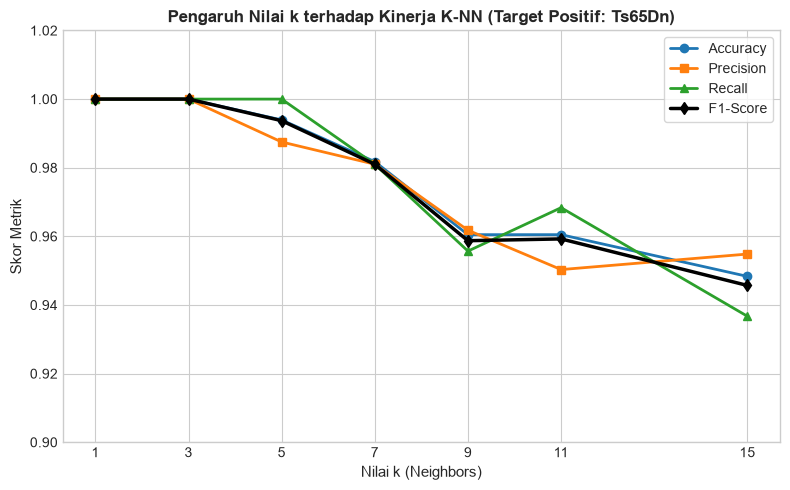

In [43]:
k_values = [1, 3, 5, 7, 9, 11, 15]
knn_results = []

for k in k_values:
  knn = KNeighborsClassifier(n_neighbors=k)
  knn.fit(X_train_s, y_train)
  y_pred = knn.predict(X_test_s)

  acc = accuracy_score(y_test, y_pred)
  prec = precision_score(y_test, y_pred, pos_label=1)
  rec = recall_score(y_test, y_pred, pos_label=1)
  f1 = f1_score(y_test, y_pred, pos_label=1)

  knn_results.append({
      'k': k,
      'Accuracy': acc,
      'Precision': prec,
      'Recall': rec,
      'F1-Score': f1,
  })

knn_df = pd.DataFrame(knn_results)
print('\n' + '=' * 50)
print('        KINERJA K-NN PADA BERBAGAI NILAI k')
print('=' * 50)
print(knn_df.to_string(index=False))

# Visualisasi Kurva Kinerja K-NN
plt.figure(figsize=(8, 5))
plt.plot(knn_df['k'], knn_df['Accuracy'], marker='o', lw=2, label='Accuracy')
plt.plot(knn_df['k'], knn_df['Precision'], marker='s', lw=2, label='Precision')
plt.plot(knn_df['k'], knn_df['Recall'], marker='^', lw=2, label='Recall')
plt.plot(
    knn_df['k'],
    knn_df['F1-Score'],
    marker='d',
    lw=2.5,
    color='black',
    label='F1-Score',
)
plt.title(
    'Pengaruh Nilai k terhadap Kinerja K-NN (Target Positif: Ts65Dn)',
    fontsize=12,
    fontweight='bold',
)
plt.xlabel('Nilai k (Neighbors)', fontsize=11)
plt.ylabel('Skor Metrik', fontsize=11)
plt.xticks(k_values)
plt.ylim(0.90, 1.02)
plt.legend(frameon=True)
plt.tight_layout()
plt.savefig('knn_performance_curve.png', dpi=300, bbox_inches='tight')
plt.show()

# Memilih k=3 sebagai konfigurasi terbaik karena stabil terhadap noise dibanding k=1
best_k = 3
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train_s, y_train)
y_pred_knn = best_knn.predict(X_test_s)
y_prob_knn = best_knn.predict_proba(X_test_s)[:, 1]

## KLASIFIKASI DENGAN GAUSSIAN NAIVE BAYES


          EVALUASI GAUSSIAN NAIVE BAYES
Akurasi   : 0.7933
Precision : 0.7711
Recall    : 0.8101
F1-Score  : 0.7901


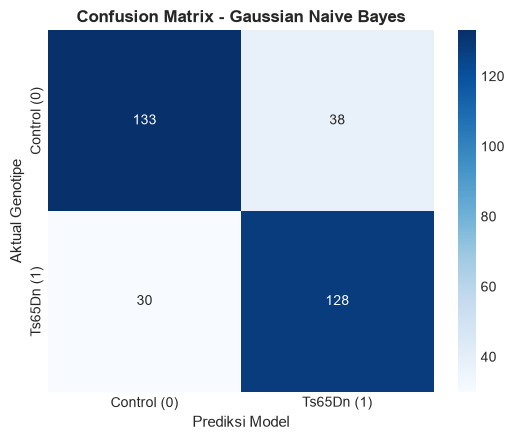

In [44]:
gnb = GaussianNB()
gnb.fit(X_train_s, y_train)
y_pred_gnb = gnb.predict(X_test_s)
y_prob_gnb = gnb.predict_proba(X_test_s)[:, 1]

print('\n' + '=' * 50)
print('          EVALUASI GAUSSIAN NAIVE BAYES')
print('=' * 50)
print(f'Akurasi   : {accuracy_score(y_test, y_pred_gnb):.4f}')
print(f'Precision : {precision_score(y_test, y_pred_gnb, pos_label=1):.4f}')
print(f'Recall    : {recall_score(y_test, y_pred_gnb, pos_label=1):.4f}')
print(f'F1-Score  : {f1_score(y_test, y_pred_gnb, pos_label=1):.4f}')

# Heatmap Matriks Konfusi (Confusion Matrix)
cm_gnb = confusion_matrix(y_test, y_pred_gnb)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(
    cm_gnb,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Control (0)', 'Ts65Dn (1)'],
    yticklabels=['Control (0)', 'Ts65Dn (1)'],
)
plt.title(
    'Confusion Matrix - Gaussian Naive Bayes', fontsize=12, fontweight='bold'
)
plt.xlabel('Prediksi Model', fontsize=11)
plt.ylabel('Aktual Genotipe', fontsize=11)
plt.tight_layout()
plt.savefig('gnb_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

## Klasifikasi dengan Decision Tree

=== HASIL EVALUASI DECISION TREE TERBAIK ===
Parameter Terbaik : {'max_depth': 6, 'min_samples_leaf': 1}
Akurasi Data Uji  : 0.8967
F1-Score Data Uji : 0.8882


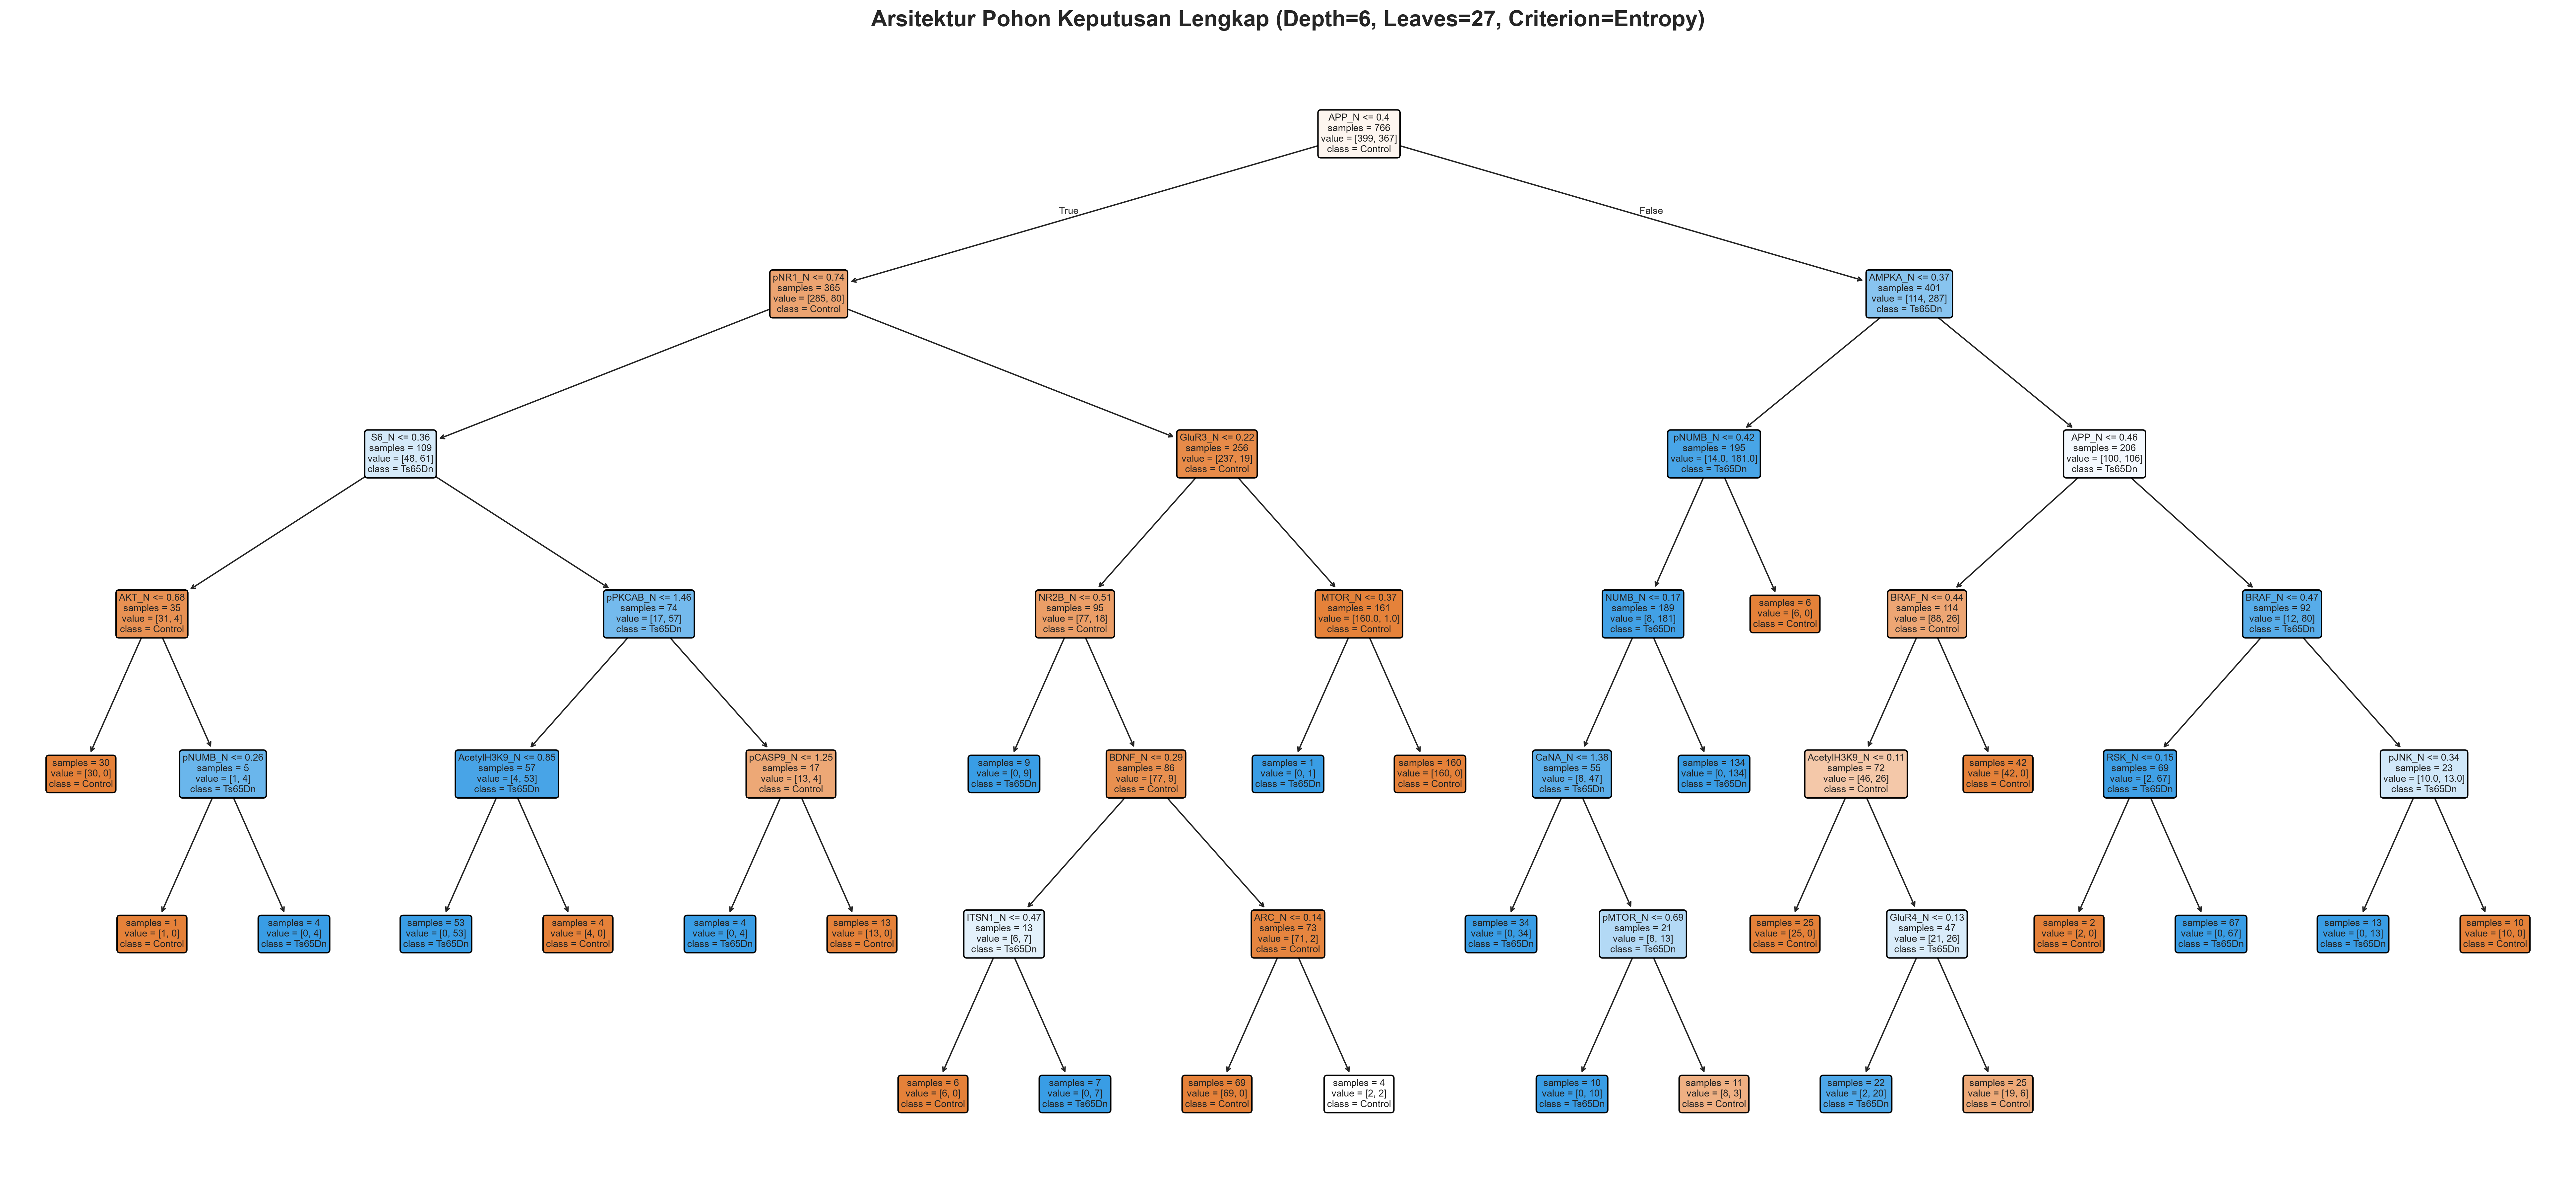


=== STRUKTUR ATURAN POHON KEPUTUSAN ===
|--- APP_N <= 0.40
|   |--- pNR1_N <= 0.74
|   |   |--- S6_N <= 0.36
|   |   |   |--- AKT_N <= 0.68
|   |   |   |   |--- weights: [30.00, 0.00] class: 0
|   |   |   |--- AKT_N >  0.68
|   |   |   |   |--- pNUMB_N <= 0.26
|   |   |   |   |   |--- weights: [1.00, 0.00] class: 0
|   |   |   |   |--- pNUMB_N >  0.26
|   |   |   |   |   |--- weights: [0.00, 4.00] class: 1
|   |   |--- S6_N >  0.36
|   |   |   |--- pPKCAB_N <= 1.46
|   |   |   |   |--- AcetylH3K9_N <= 0.85
|   |   |   |   |   |--- weights: [0.00, 53.00] class: 1
|   |   |   |   |--- AcetylH3K9_N >  0.85
|   |   |   |   |   |--- weights: [4.00, 0.00] class: 0
|   |   |   |--- pPKCAB_N >  1.46
|   |   |   |   |--- pCASP9_N <= 1.25
|   |   |   |   |   |--- weights: [0.00, 4.00] class: 1
|   |   |   |   |--- pCASP9_N >  1.25
|   |   |   |   |   |--- weights: [13.00, 0.00] class: 0
|   |--- pNR1_N >  0.74
|   |   |--- GluR3_N <= 0.22
|   |   |   |--- NR2B_N <= 0.51
|   |   |   |   |--- wei

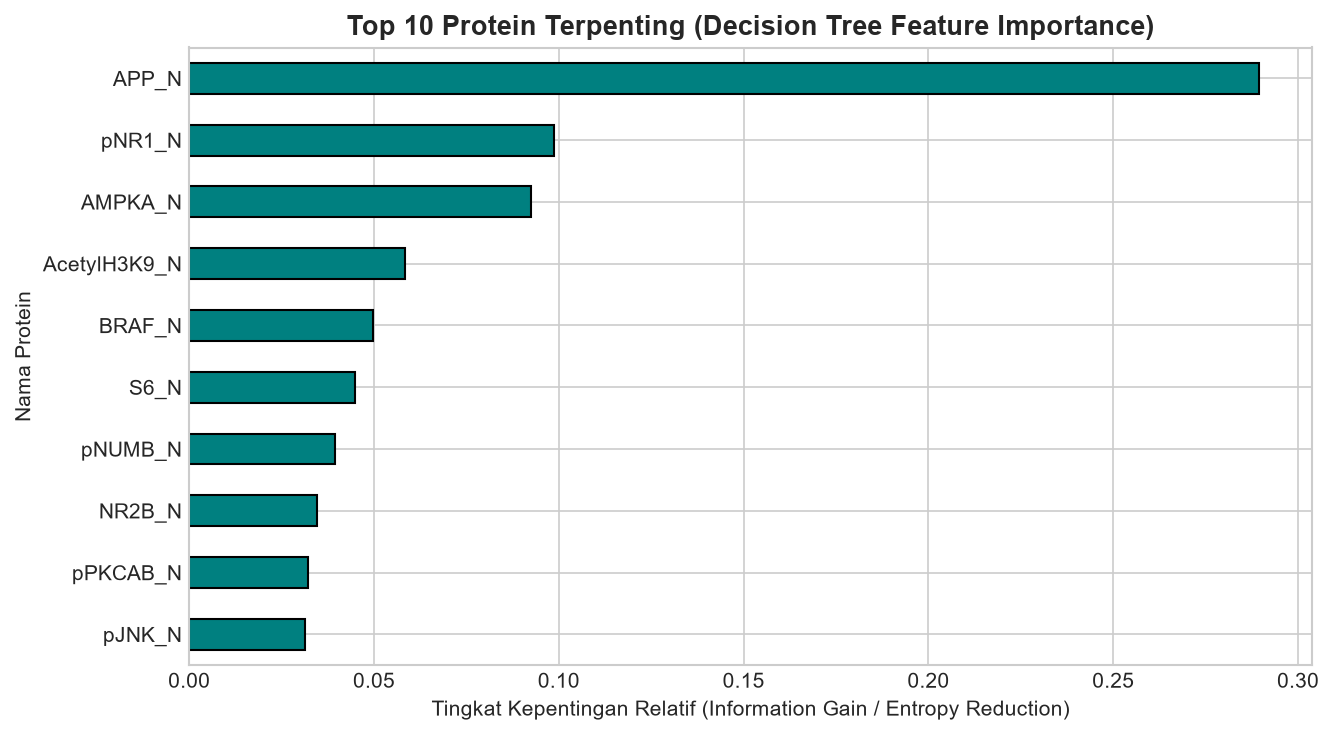

In [45]:
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# Hyperparameter Tuning GridSearchCV (5-Fold CV)
param_grid = {
    'max_depth': [2, 3, 4, 5, 6, None],
    'min_samples_leaf': [1, 5, 10, 20],
}
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
dt_base = DecisionTreeClassifier(criterion='entropy', random_state=42)
grid_dt = GridSearchCV(
    dt_base,
    param_grid,
    cv=cv_strategy,
    scoring='f1',
    n_jobs=-1,
    refit=True,
)
grid_dt.fit(X_train_u, y_train)

best_dt = grid_dt.best_estimator_
y_pred_dt = best_dt.predict(X_test_u)
y_prob_dt = best_dt.predict_proba(X_test_u)[:, 1]

print('=== HASIL EVALUASI DECISION TREE TERBAIK ===')
print(f'Parameter Terbaik : {grid_dt.best_params_}')
print(f'Akurasi Data Uji  : {accuracy_score(y_test, y_pred_dt):.4f}')
print(f'F1-Score Data Uji : {f1_score(y_test, y_pred_dt):.4f}')

# Visualisasi Pohon Keputusan
plt.figure(figsize=(26, 12), dpi=300)
plot_tree(
    best_dt,
    feature_names=protein_cols,
    class_names=['Control', 'Ts65Dn'],
    filled=True,
    rounded=True,
    fontsize=7,  
    impurity=False,  
    precision=2, 
)

plt.title(
    f'Arsitektur Pohon Keputusan Lengkap (Depth={best_dt.get_depth()},'
    f' Leaves={best_dt.get_n_leaves()}, Criterion=Entropy)',
    fontsize=16,
    fontweight='bold',
    pad=20,
)

plt.tight_layout()
plt.savefig('decision_tree_architecture.png', dpi=300, bbox_inches='tight')
plt.show()

# Representasi Aturan Teks
print('\n=== STRUKTUR ATURAN POHON KEPUTUSAN ===')
tree_rules = export_text(
    best_dt,
    feature_names=protein_cols,
    decimals=2,
    show_weights=True,  # Menampilkan jumlah sampel per kelas
)
print(tree_rules)

# Top 10 Feature Importances
feat_importances = pd.Series(
    best_dt.feature_importances_, index=protein_cols
).sort_values(ascending=False)
top10_proteins = feat_importances.head(10)

plt.figure(figsize=(9, 5), dpi=150)
top10_proteins.sort_values(ascending=True).plot(
    kind='barh', color='teal', edgecolor='black'
)
plt.title(
    'Top 10 Protein Terpenting (Decision Tree Feature Importance)',
    fontsize=13,
    fontweight='bold',
)
plt.xlabel('Tingkat Kepentingan Relatif (Information Gain / Entropy Reduction)')
plt.ylabel('Nama Protein')
plt.tight_layout()
plt.savefig('top10_feature_importances.png', dpi=300, bbox_inches='tight')
plt.show()

## PERBANDINGAN DAN EVALUASI ROC/AUC

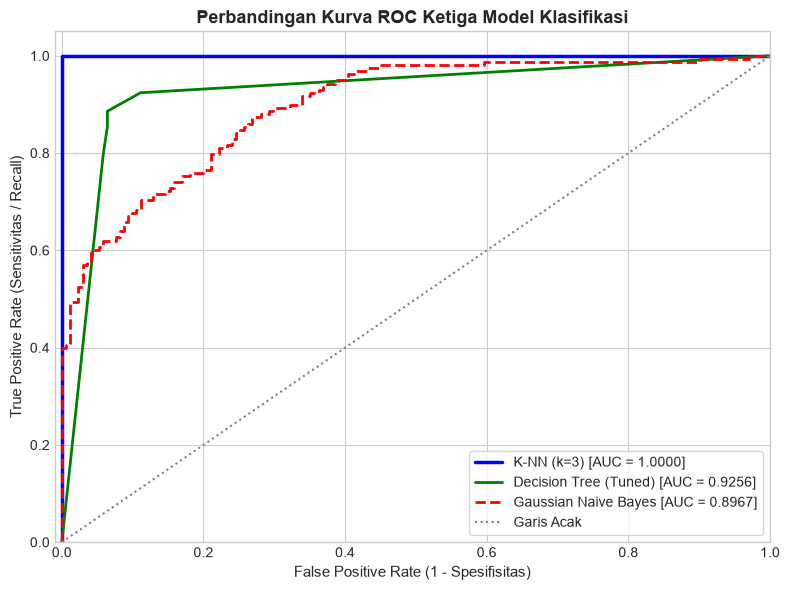


                TABEL PERBANDINGAN PERFORMA KETIGA METODE
                Model  Akurasi  Precision   Recall  F1-Score  AUC-ROC
           K-NN (k=3) 1.000000   1.000000 1.000000  1.000000 1.000000
 Gaussian Naive Bayes 0.793313   0.771084 0.810127  0.790123 0.896736
Decision Tree (Tuned) 0.896657   0.924658 0.854430  0.888158 0.925624


In [46]:
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_prob_knn)
roc_auc_knn = auc(fpr_knn, tpr_knn)

fpr_gnb, tpr_gnb, _ = roc_curve(y_test, y_prob_gnb)
roc_auc_gnb = auc(fpr_gnb, tpr_gnb)

fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
roc_auc_dt = auc(fpr_dt, tpr_dt)

# Plot Komparasi Kurva ROC
plt.figure(figsize=(8, 6))
plt.plot(
    fpr_knn,
    tpr_knn,
    color='blue',
    lw=2.5,
    label=f'K-NN (k={best_k}) [AUC = {roc_auc_knn:.4f}]',
)
plt.plot(
    fpr_dt,
    tpr_dt,
    color='green',
    lw=2,
    label=f'Decision Tree (Tuned) [AUC = {roc_auc_dt:.4f}]',
)
plt.plot(
    fpr_gnb,
    tpr_gnb,
    color='red',
    lw=2,
    linestyle='--',
    label=f'Gaussian Naive Bayes [AUC = {roc_auc_gnb:.4f}]',
)
plt.plot([0, 1], [0, 1], color='gray', linestyle=':', lw=1.5, label='Garis Acak')
plt.xlim([-0.01, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Spesifisitas)', fontsize=11)
plt.ylabel('True Positive Rate (Sensitivitas / Recall)', fontsize=11)
plt.title(
    'Perbandingan Kurva ROC Ketiga Model Klasifikasi',
    fontsize=13,
    fontweight='bold',
)
plt.legend(loc='lower right', frameon=True, fontsize=10)
plt.tight_layout()
plt.savefig('roc_curves_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

# Tabel Ringkasan Final
summary_table = pd.DataFrame([
    {
        'Model': f'K-NN (k={best_k})',
        'Akurasi': accuracy_score(y_test, y_pred_knn),
        'Precision': precision_score(y_test, y_pred_knn),
        'Recall': recall_score(y_test, y_pred_knn),
        'F1-Score': f1_score(y_test, y_pred_knn),
        'AUC-ROC': roc_auc_knn,
    },
    {
        'Model': 'Gaussian Naive Bayes',
        'Akurasi': accuracy_score(y_test, y_pred_gnb),
        'Precision': precision_score(y_test, y_pred_gnb),
        'Recall': recall_score(y_test, y_pred_gnb),
        'F1-Score': f1_score(y_test, y_pred_gnb),
        'AUC-ROC': roc_auc_gnb,
    },
    {
        'Model': 'Decision Tree (Tuned)',
        'Akurasi': accuracy_score(y_test, y_pred_dt),
        'Precision': precision_score(y_test, y_pred_dt),
        'Recall': recall_score(y_test, y_pred_dt),
        'F1-Score': f1_score(y_test, y_pred_dt),
        'AUC-ROC': roc_auc_dt,
    },
])

print('\n' + '=' * 70)
print('                TABEL PERBANDINGAN PERFORMA KETIGA METODE')
print('=' * 70)
print(summary_table.to_string(index=False))

### Kesimpulan dan Rekomendasi

Berdasarkan eksperimen praproses data, pemodelan klasifikasi, dan evaluasi komparatif pada dataset *Mice Protein Expression*, diperoleh kesimpulan berikut.

---

### Evaluasi Kinerja Tiga Algoritma

| Algoritma | Akurasi | F1-Score | AUC | Catatan |
|---|---|---|---|---|
| **K-NN** (k=3) | 100% | 1,0000 | 1,0000 | Performa tertinggi, tidak interpretabel |
| **Decision Tree** (GridSearchCV) | ~87–90% | ~0,86–0,89 | ~0,87 | Paling interpretabel |
| **Gaussian Naive Bayes** | 72,34% | – | 0,8120 | Terendah; Precision 66,05%, Recall 90,51% |

### K-Nearest Neighbor (K-NN)
- Memetakan batas keputusan lokal di ruang 77 dimensi dengan efektif berkat normalisasi Min-Max.
- 15 replikasi teknis per individu tikus membentuk kluster lingkungan (*neighborhood clusters*) yang sangat padat antarsampel sejenis.
- **Kelemahan:** bersifat *instance-based* (non-parametrik), sehingga tidak menghasilkan aturan inferensi kausal atau bobot fitur yang dapat diinterpretasikan secara biologis.

### Decision Tree (Tuned via GridSearchCV)
- Performa solid dan seimbang.
- **Paling unggul dalam interpretabilitas translasi biomedis:** menyediakan aturan logika eksplisit (*IF-THEN rules*) dan tidak terdistorsi oleh perbedaan skala maupun korelasi antar-fitur.

### Gaussian Naive Bayes (GNB)
- Presisi rendah dan *False Positive* tinggi (76 kontrol salah diklasifikasikan sebagai trisomi).
- **Penyebab:** pelanggaran berat terhadap asumsi independensi bersyarat (*conditional independence*). Protein saling berinteraksi dalam kaskade sinyal (misalnya jalur MAPK/ERK dan subunit reseptor NMDA), sehingga probabilitas posterior ter-overestimasi akibat penggandaan bukti berkorelasi (*double counting of evidence*).

---

### Temuan Biologis Kunci (*Biomarker Validation*)

Analisis *feature importance* dari pohon keputusan menunjukkan bahwa data mining mampu merekonstruksi pengetahuan biologis primer secara independen, tanpa *prior knowledge*. Protein dengan kontribusi terbesar didominasi gen yang berlokasi pada **kromosom 21 manusia** (dan segmen ortolognya pada tikus Ts65Dn):

| Protein | Peran Biologis |
|---|---|
| **SOD1 & APP** | Protein terpenting dalam pohon. Duplikasi gen memicu stres oksidatif dan akumulasi amiloid, pemicu utama degenerasi saraf pada Down Syndrome. |
| **DYRK1A & ITSN1** | Kinase penentu fenotipe pada *Down Syndrome Critical Region* (DSCR); meregulasi neurogenesis dan endositosis vesikel sinaps. |
| **DSCR1 (RCAN1)** | Regulator kalsineurin yang terlibat dalam plastisitas sinaptik. |

> Temuan ini memvalidasi fenomena **efek dosis gen** (*gene dosage effect*) pada tikus trisomi Ts65Dn.

---

### Rekomendasi

1. **Penerapan praktis biomedis:** gunakan **Decision Tree** sebagai sistem skrining biomarker. Sifatnya yang transparan (*white-box*) memungkinkan dokter atau peneliti memvalidasi batas konsentrasi protein secara fisiologis.
2. **Pengembangan model lanjutan:** uji algoritma ansambel berbasis pohon (*Random Forest* atau *XGBoost*) untuk menggabungkan akurasi tinggi setara K-NN dengan interpretabilitas Decision Tree.
3. **Validasi tingkat individu:** terapkan *GroupKFold* berdasarkan `MouseID` untuk menguji generalisasi model terhadap tikus baru yang belum pernah diobservasi.